<a href="https://colab.research.google.com/github/senaymarcos/BazaarX/blob/main/Assignments/Part%201/Assignment_part_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DSML investigation:
### You are part of the Suisse Impossible Mission Force, or SIMF for short. You need to uncover a rogue agent that is trying to steal sensitive information.

### Your mission, should you choose to accept it, is to find that agent before any classified information gets stolen. Good luck!


## Assignment part one

Airport security confiscated a laptop of a spy, which was later given to you. The laptop contains some documents that might be useful in the investigation process. You retrieve those documents and want to analyse them. Our intelligence shows that the person that we are looking for has visited the USA between Sept 2019 to Oct 2020. He is currently working undercover.


### Getting to know our data

We have retrieved from the laptop the following file:
- A list of suspects
- The flight records of these potential suspects



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
userRecords = pd.read_csv("https://raw.githubusercontent.com/michalis0/DataScience_and_MachineLearning/refs/heads/master/Assignments/Part%201/data/userRecords.csv")
travelRecords = pd.read_csv("https://raw.githubusercontent.com/michalis0/DataScience_and_MachineLearning/refs/heads/master/Assignments/Part%201/data/flightRecords.csv")

In [ ]:
userRecords

,UserID,first_name,last_name,birthday,country,marital_status,number_of_kids,employment
0,317991,Lu***,Al*****,29.07.03,AR,1,2.0,Web Designer
1,241892,Ma****,Ro*******,10.11.99,AR,1,0.0,Banker
2,303376,Fr****,Ac****,25.07.84,AR,1,0.0,Kitchen staff
3,761992,Fr****,Go***,20.03.70,AR,1,0.0,Teaching Assistant
4,373318,Jo***,Ro***,05.10.71,AR,1,0.0,Administrative employee
...,...,...,...,...,...,...,...,...
952,218415,Bu******,Mo******,22.01.01,ZA,0,1.0,Web Designer
953,173906,Th*****,Mo******,06.11.61,ZA,0,2.0,Web Designer
954,178685,Mi*****,Bu*******,29.05.53,ZA,0,1.0,Professor
955,200865,Si*******,Na****,16.12.62,ZA,0,0.0,Web Designer


In [3]:
travelRecords[travelRecords["userID"] == 317991]

,flightName,departure,destination,date,userID
0,KX65826,AR,IT,20.01.10,317991
1,CL12336,IT,MT,16.06.10,317991
2,YN106988,MT,SE,08.05.11,317991
3,CB58289,SE,EE,08.11.11,317991
4,SX625101,EE,AZ,17.11.11,317991
5,FI81778,AZ,ES,19.01.12,317991
6,WL73165,ES,RU,24.02.12,317991
7,NG103876,RU,JP,28.06.12,317991
8,IX62714,JP,AT,24.07.12,317991
9,BT46823,AT,GB,25.08.12,317991


#### Shape of the data

Let's first check how many rows and columns (features) are in the user records

In [4]:
#Your code here
userRecords.shape

(957, 8)

**Q1. How many rows are there in the user records dataset?**

957 rows in the user records and 8 columns


#### Check out the first few rows
Print the first few rows of the user records dataset and check them. Note that to protect innocent people, the name of the suspects have been censored, those will be revealed once number of potential suspects decreases.


In [5]:
#Your code here
userRecords.head()

,UserID,first_name,last_name,birthday,country,marital_status,number_of_kids,employment
0,317991,Lu***,Al*****,29.07.03,AR,1,2.0,Web Designer
1,241892,Ma****,Ro*******,10.11.99,AR,1,0.0,Banker
2,303376,Fr****,Ac****,25.07.84,AR,1,0.0,Kitchen staff
3,761992,Fr****,Go***,20.03.70,AR,1,0.0,Teaching Assistant
4,373318,Jo***,Ro***,05.10.71,AR,1,0.0,Administrative employee


#### Column/feature names
print the list of columns in the user records dataset.

In [6]:
#Your code here
userRecords.columns

Index(['UserID', 'first_name', 'last_name', 'birthday', 'country',
       'marital_status', 'number_of_kids', 'employment'],
      dtype='object')

#### Duplicates
Check if there are any duplicate entries in the user records dataset.

__Remark__: If there are two rows in the dataset that have the same value for __all of the columns__, we consider this as a duplicate.

In [2]:
#Your code here
userRecords[userRecords.duplicated()== True]

,UserID,first_name,last_name,birthday,country,marital_status,number_of_kids,employment
19,100684,Ma*****,Me****,17.06.76,AR,NaN,0.0,Administrative employee
165,910382,Ni***,El****,21.03.75,AZ,NaN,0.0,Administrative employee
290,610518,An*****,An******,15.02.53,DK,1,NaN,Manager


Show all the duplicated rows in the user records dataset.

__Hint:__ use the method `duplicated(keep=False)` to get all occurrences of the duplicated rows.

In [3]:
#Your code here
userRecords[userRecords.duplicated(keep=False)== True]

,UserID,first_name,last_name,birthday,country,marital_status,number_of_kids,employment
18,100684,Ma*****,Me****,17.06.76,AR,NaN,0.0,Administrative employee
19,100684,Ma*****,Me****,17.06.76,AR,NaN,0.0,Administrative employee
47,910382,Ni***,El****,21.03.75,AZ,NaN,0.0,Administrative employee
165,910382,Ni***,El****,21.03.75,AZ,NaN,0.0,Administrative employee
276,610518,An*****,An******,15.02.53,DK,1,NaN,Manager
290,610518,An*****,An******,15.02.53,DK,1,NaN,Manager


**Q2. Are there any duplicate entries in the user records dataset?**  
Yes, there are 3 duplicate entries in the user
records.
*Note: Duplicate entries refer to two or more rows where all the values across every column are identical.*

**Q3. How many duplicate entries are in the user records dataset?**
3 duplicate entries are in the user records.
(Remark: for instance: there are 2 duplicate "entries" in the following list: '1 ,2, 1, 3, 3, 4, 5'. It's 1 and 3).

Drop the duplicate entries in the user records dataset.

In [9]:
#Your code here
delete_duplcated_rows = userRecords[userRecords.duplicated() == True]

userRecords = userRecords.drop(delete_duplcated_rows.index, axis=0)

### Spies often use false identities with fabricated data.

#### This suggests that if certain data points occur with statistically improbable frequency, they might be fabricated.

In this part we are going to verify if there are birthdates that have been reused an unusual amount of times.

Let's first ensure that the birthday column in the user records dataset has the correct format (datetime):


In [10]:
#Check the data type of each feature
#Your code here
userRecords["birthday"].dtype

dtype('O')

Convert the column `birthday` to datetime if necessary

In [12]:
#Your code here
userRecords['birthday'] = pd.to_datetime(userRecords['birthday'], format="%d.%m.%y")

Find the list of birthdays that are duplicated/reused in the dataset

In [11]:
#Your code here
userRecords[userRecords.duplicated(keep=False)]

,UserID,first_name,last_name,birthday,country,marital_status,number_of_kids,employment


Let's count how many people have their birthday on the same day among the duplicated birthdays.

In [13]:
#Your code here
duplicated_birthday = userRecords[userRecords["birthday"].duplicated(keep = False)].sort_values("birthday")

duplicated_birthday["birthday"]

duplicated_birthday["birthday"].shape

duplicated_birthday["birthday"].value_counts().sort_values(ascending = False)

,count
birthday,
1992-06-01,4
1970-03-18,2
1975-01-28,2
1978-11-21,2
1983-03-15,2
1970-04-06,2
1983-08-26,2
1991-12-02,2
1999-08-09,2


**Q4. What is the most common birthday in the dataset?**
birthday
1992-06-01    4
1970-03-18    2
1975-01-28    2
1978-11-21    2 , so most common birthday : 1992-06-01    4

**Q5. How many users have their birthdays on that day (the most common birthday)?**

4

We can consider that there is no suspicious discrepancy through birthdays.


#### We have reasons to believe that the suspect works very thoroughly, so he would make sure that the fabricated data about his identity is complete in order for his operation to run smoothly.
#### Therefore, we can exclude the people with incomplete information from the list of potential suspects.

Count how many null values are there in each column of the user records dataset. You can call `isnull()` and `sum()` to get a count of how many null values are there in each column.

In [6]:
#Your code here
userRecords.isnull().sum()

,0
UserID,0
first_name,1
last_name,1
birthday,1
country,0
marital_status,104
number_of_kids,153
employment,1


If you encounter any null values in the dataset, be sure to exclude those entries from the suspect list.

In [7]:
#Your code here
userRecords = userRecords.dropna()

### Linking the user records to the flight records

We will now proceed to identify the users who were in the USA from Sept 1st, 2019 to Oct 31st, 2020.

We will merge the flight records with the user records in order to ensure that users who have been unsuspected in the previous step are not considered.

In [8]:
#check the user records dataset

userRecords

,UserID,first_name,last_name,birthday,country,marital_status,number_of_kids,employment
0,317991,Lu***,Al*****,29.07.03,AR,1,2.0,Web Designer
1,241892,Ma****,Ro*******,10.11.99,AR,1,0.0,Banker
2,303376,Fr****,Ac****,25.07.84,AR,1,0.0,Kitchen staff
3,761992,Fr****,Go***,20.03.70,AR,1,0.0,Teaching Assistant
4,373318,Jo***,Ro***,05.10.71,AR,1,0.0,Administrative employee
...,...,...,...,...,...,...,...,...
950,458293,No********,Wi******,26.03.54,ZA,1,2.0,Professor
952,218415,Bu******,Mo******,22.01.01,ZA,0,1.0,Web Designer
953,173906,Th*****,Mo******,06.11.61,ZA,0,2.0,Web Designer
954,178685,Mi*****,Bu*******,29.05.53,ZA,0,1.0,Professor


In [9]:
#check the flight records dataset
travelRecords

,flightName,departure,destination,date,userID
0,KX65826,AR,IT,20.01.10,317991
1,CL12336,IT,MT,16.06.10,317991
2,YN106988,MT,SE,08.05.11,317991
3,CB58289,SE,EE,08.11.11,317991
4,SX625101,EE,AZ,17.11.11,317991
...,...,...,...,...,...
25394,BM96341,PR,DE,31.10.20,102637
25395,SA710311,DE,CR,14.09.21,102637
25396,BB83468,CR,DK,22.11.21,102637
25397,ZS810988,DK,ES,05.09.22,102637


[Merging](https://pandas.pydata.org/docs/user_guide/merging.html) the two datasets:

*Hint: Use the above questions to identify on what feature to merge the datasets*

The result should contain the features flightName, Departure, Arrival,  Date, UserID, first_name, last_name, etc.

In [10]:
#Your code here
userTravelRecords = pd.merge(userRecords, travelRecords,  left_on='UserID', right_on='userID')

Remember, our suspect operates meticulously, ensuring that there are no null values in any entries.

In [19]:
#Your code here
userTravelRecords.isnull().sum()

,0
UserID,0
first_name,0
last_name,0
birthday,0
country,0
marital_status,0
number_of_kids,0
employment,0
flightName,0
departure,0


Let's now identify the users who has **travelled to** the United States (US) between the 1st of september 2019 and the 31st of october 2020.

*Note that the travel date is not in datetime format.*

In [14]:
#Your code here
userTravelRecords['date'] = pd.to_datetime(userTravelRecords['date'], format="%d.%m.%y")

suspects_traveller = userTravelRecords[userTravelRecords["date"].between("2019-09-01", "2020-10-31")]
suspects_traveller_destination = suspects_traveller[suspects_traveller["destination"] == "US" ]

suspects_traveller_destination


,UserID,first_name,last_name,birthday,country,marital_status,number_of_kids,employment,flightName,departure,destination,date,userID
246,468560,Ga******,Fe*******,18.04.60,AR,1,2.0,Lawyer,MG891910,AR,US,2020-07-16,468560
463,255830,Ch*******,Be****,26.12.59,AT,1,1.0,Professor,OO3731010,CA,US,2020-04-10,255830
958,861915,Ay***,Al*****,26.02.78,AZ,0,1.0,Doctor,GU84573,ES,US,2020-02-10,861915
2289,220420,Ma*****,So****,23.12.84,BR,0,3.0,Web Designer,TF469810,IT,US,2020-03-17,220420
2702,297653,Br***,Wo**,22.09.68,CA,1,0.0,Lawyer,MX97137,FR,US,2020-07-23,297653
4089,710764,Ra*****,He*******,27.05.76,CR,0,4.0,Manager,NY87398,BE,US,2019-09-17,710764
4897,267733,Sø***,Ma****,14.09.98,DK,0,0.0,Kitchen staff,HX23943,CO,US,2020-10-10,267733
5349,429697,Li**,Re****,28.07.59,EE,1,3.0,Administrative employee,JE532410,CH,US,2020-06-26,429697
7179,649131,Ju***,Wi****,04.07.91,GB,1,3.0,Banker,LY781032,BR,US,2020-04-18,649131
7451,481578,Br****,De*****,31.07.63,GT,1,0.0,Administrative employee,PP35996,HU,US,2020-05-03,481578


**Q6. How many suspects travelled to the US between the 1st of September 2019 and the 31st of October 2020?**  32 suspects travelled to US between those date.

**Q7. Which users are included in the remaining list of suspects who traveled to the US between the 1st of September 2019 and the 31st of October 2020?** Choose from the answers on Moodle.

## [Data visualisation ](https://pandas.pydata.org/docs/user_guide/visualization.html)

 Suisse Impossible Mission Force is happy with the result and would like to have some visual aid to make a profile of the potential suspects.

Let's create a pie chart to visualize the employment distribution among the suspects who traveled to US between September 1st, 2019, and October 31st, 2020.

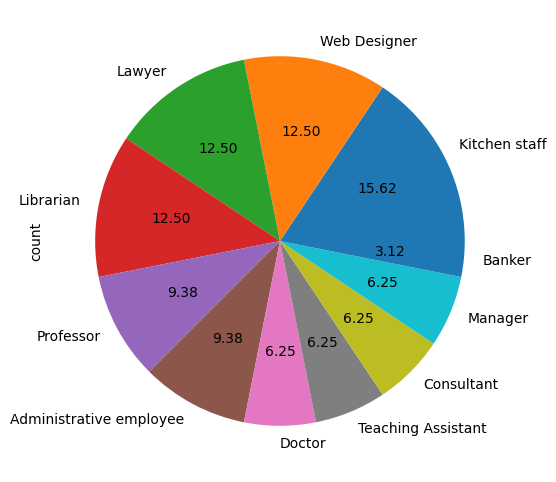

In [30]:
#Your code here

series = pd.Series(suspects_traveller_destination["employment"].to_list())

series.value_counts().plot.pie(autopct="%.2f",figsize=(6, 6));


**Q8. Which profession is the least represented among the suspects who traveled to US between September 1st, 2019, and October 31st, 2020?**
 Choose from the answers on Moodle.
---Banker is the least represented among the suuspects

## Journey length

The Suisse Impossible Mission Force suspects that the rogue agent is an anomaly within his declared employment category, particularly in terms of the number of days he spent at destinations compared to his peers.

To identify such deviations, we can employ boxplots for each employment category, allowing us to visually identify outliers in the data.

First, let's construct two tables: one for the dates of arrival and another for the dates of departure. Utilize the existing dataset to extract these dates based on the 'destination' and 'departure' columns. Ensure that both the arrival and departure dates are within the period the suspect is believed to have been in the US, which is from September 2019 to October 2020.

In [40]:
# For this step we will need the information not only about the flights to the US,
# but also about the flights taken from the US
# Your code here
suspects_traveller_departure = suspects_traveller[suspects_traveller["departure"]== "US"]
suspects_traveller_destination.shape
suspects_traveller_departure.shape

We can keep on both of these tables the user ID, employment, and departure date / arrival date.

In [44]:
#Your code here
df_arrival = suspects_traveller_destination[['UserID', 'employment', 'date']].rename( columns={'date': 'arrival_date'})
df_departure= suspects_traveller_departure[['UserID', 'date']].rename( columns={'date': 'departure_date'})



We can now join the two tables on user ID.

In [43]:
#Your code here

df_combined = pd.merge(df_arrival, df_departure, on = "UserID")

We can now create a new feature called journey_length representing the difference between departure date and arrival date.

*Hint: Ensure that the journey_length is in the right format*

In [38]:
#Your code here

df_combined["journey_length"] =  (df_combined['departure_date'] - df_combined['arrival_date']).dt.days

*Sidenote: if you get negative journey length, what would be your explanation to that?*
--- Logically, this is not possible; perhaps there was a data entry error or incorrect information.

We can now create the boxplots where the x-axis represents each profession and the y-axis corresponds to the journey length.

In [ ]:
#Your code here
fig, ax = plt.subplots(figsize=(12, 6))
df_combined.boxplot(column='journey_length', by='employment', ax = ax, rot = 45)
plt.title('Journey Length by Employment')
plt.xlabel('Employment')
plt.ylabel('Journey Length (days)')
plt.show()

**Q9. Which profession has the most staggering outlier?**
(Meaning that the outlier value is the farthest away from the corresponding boxplot.)

### SIMF is satisfied with your work but believes the current data is inconclusive.

Your investigation will continue when more intelligence comes in...

**Don't forget to complete the moodle quiz ([Assignment Q1](https://moodle.unil.ch/mod/quiz/view.php?id=1744562)) and submit your code ([Code Q1](https://moodle.unil.ch/mod/assign/view.php?id=1744563)) on Moodle before Monday 30.09.2024.**